In [4]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [9]:
# Load the data
df = pd.read_csv("/content/OnlineNewsPopularity.csv")
df.columns = df.columns.str.strip()   # column names in this file start with a space

print("Number of articles:", len(df))
print("Missing values:", df.isnull().sum().sum())

# Overall shares
print("\n--- Shares overall ---")
print("Average:", round(df["shares"].mean()))
print("Median:", round(df["shares"].median()))
print("Minimum:", df["shares"].min())
print("Maximum:", df["shares"].max())

# Content category (combine the six category columns into one)
names = {"lifestyle": "Lifestyle", "entertainment": "Entertainment", "bus": "Business",
         "socmed": "Social media", "tech": "Technology", "world": "World news"}
df["category"] = "Other"
for col, label in names.items():
    df.loc[df["data_channel_is_" + col] == 1, "category"] = label

print("\n--- Shares by content category ---")
by_category = df.groupby("category")["shares"].agg(["count", "mean", "median"]).round(0)
by_category.columns = ["Number of articles", "Average shares", "Median shares"]
print(by_category.sort_values("Average shares", ascending=False))

# Weekday versus weekend
print("\n--- Shares by day published ---")
by_day = df.groupby("is_weekend")["shares"].agg(["count", "mean", "median"]).round(0)
by_day.index = ["Weekday", "Weekend"]
by_day.columns = ["Number of articles", "Average shares", "Median shares"]
print(by_day)

# Keyword strength
df["log_shares"] = np.log(df["shares"])
print("\n--- Keyword strength ---")
print("Median keyword strength:", round(df["kw_avg_avg"].median()))
print("Correlation with logarithm of shares:", round(df["kw_avg_avg"].corr(df["log_shares"]), 2))

FileNotFoundError: [Errno 2] No such file or directory: '/content/OnlineNewsPopularity.csv'

In [10]:
from google.colab import files
uploaded = files.upload()

import os
csv_name = [f for f in os.listdir() if f.endswith(".csv")][0]
os.rename(csv_name, "OnlineNewsPopularity.csv")
print("Ready:", os.listdir())

Saving OnlineNewsPopularity.csv to OnlineNewsPopularity.csv
Ready: ['.config', 'OnlineNewsPopularity.csv', 'sample_data']


Number of articles: 39644
Missing values: 0

--- Shares overall ---
Average: 3395
Median: 1400
Minimum: 1
Maximum: 843300

--- Shares by content category ---
               Number of articles  Average shares  Median shares
category                                                        
Other                        6134          5945.0         1900.0
Lifestyle                    2099          3682.0         1700.0
Social media                 2323          3629.0         2100.0
Technology                   7346          3072.0         1700.0
Business                     6258          3063.0         1400.0
Entertainment                7057          2970.0         1200.0
World news                   8427          2288.0         1100.0

--- Shares by day published ---
         Number of articles  Average shares  Median shares
Weekday               34454          3319.0         1400.0
Weekend                5190          3903.0         1900.0

--- Keyword strength ---
Median keyword streng

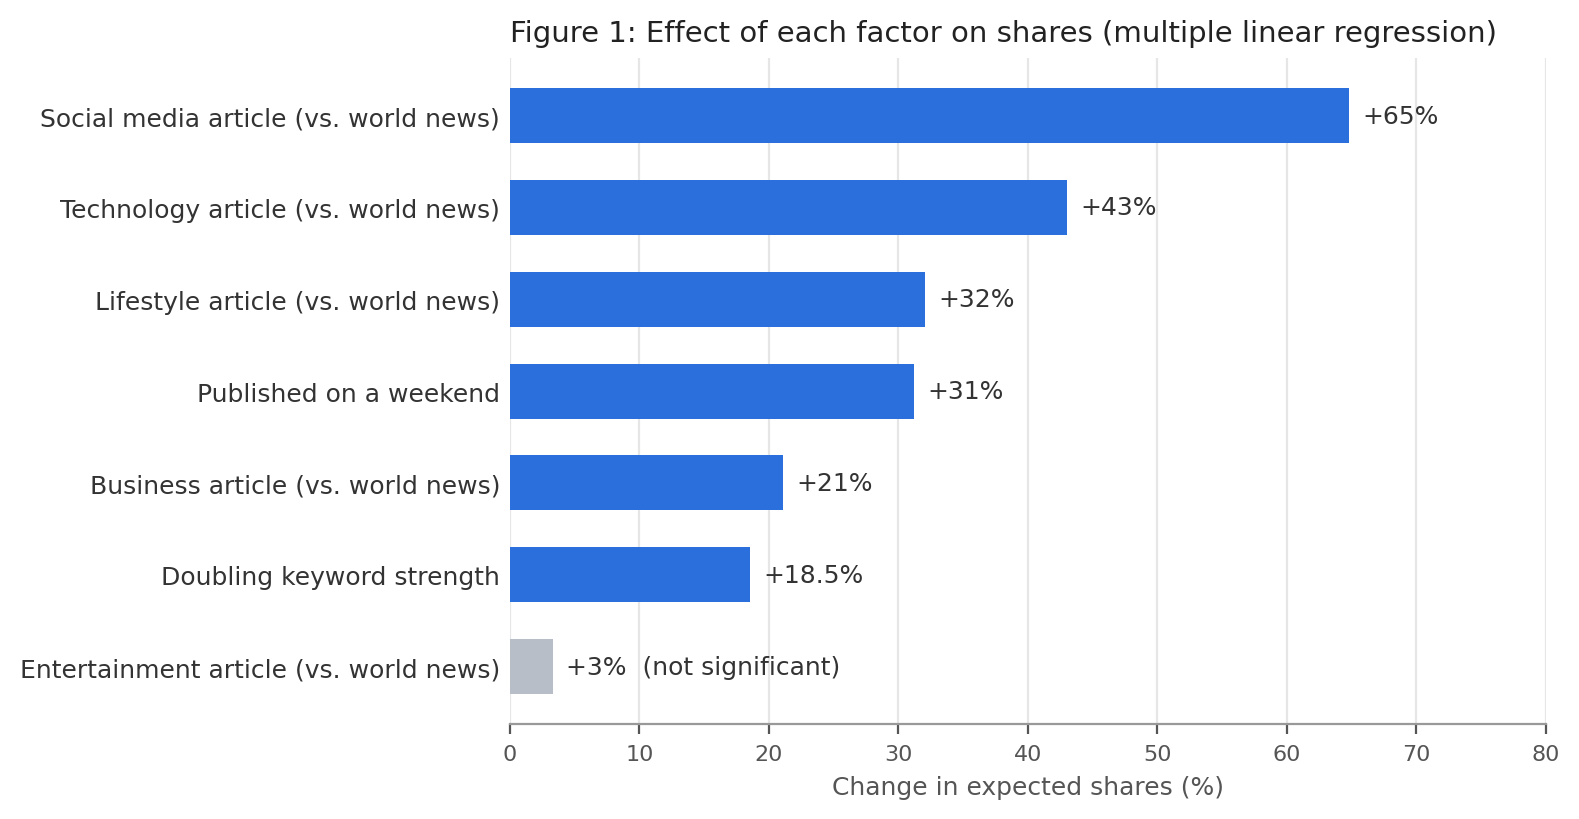

In [11]:
# ============================================================
# Draft Report: Online News Popularity (full code)
# ============================================================
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# ---------- Part 1: Load the data ----------
df = pd.read_csv("OnlineNewsPopularity.csv")
df.columns = df.columns.str.strip()   # column names in this file start with a space

print("Number of articles:", len(df))
print("Missing values:", df.isnull().sum().sum())

# ---------- Part 2: Summary statistics ----------
print("\n--- Shares overall ---")
print("Average:", round(df["shares"].mean()))
print("Median:", round(df["shares"].median()))
print("Minimum:", df["shares"].min())
print("Maximum:", df["shares"].max())

# Combine the six category columns into one column
names = {"lifestyle": "Lifestyle", "entertainment": "Entertainment", "bus": "Business",
         "socmed": "Social media", "tech": "Technology", "world": "World news"}
df["category"] = "Other"
for col, label in names.items():
    df.loc[df["data_channel_is_" + col] == 1, "category"] = label

print("\n--- Shares by content category ---")
by_category = df.groupby("category")["shares"].agg(["count", "mean", "median"]).round(0)
by_category.columns = ["Number of articles", "Average shares", "Median shares"]
print(by_category.sort_values("Average shares", ascending=False))

print("\n--- Shares by day published ---")
by_day = df.groupby("is_weekend")["shares"].agg(["count", "mean", "median"]).round(0)
by_day.index = ["Weekday", "Weekend"]
by_day.columns = ["Number of articles", "Average shares", "Median shares"]
print(by_day)

# Shares are very skewed, so the models use the logarithm of shares
df["log_shares"] = np.log(df["shares"])
print("\n--- Keyword strength ---")
print("Median keyword strength:", round(df["kw_avg_avg"].median()))
print("Correlation with logarithm of shares:", round(df["kw_avg_avg"].corr(df["log_shares"]), 2))

# ---------- Part 3: Training set (70%) and test set (30%) ----------
train, test = train_test_split(df, test_size=0.3, random_state=1)
print("\nTraining articles:", len(train), "| Test articles:", len(test))

# ---------- Part 4: Multiple linear regression ----------
formula = ("log_shares ~ C(category, Treatment('World news')) + np.log1p(kw_avg_avg) + is_weekend"
           " + num_imgs + num_videos + n_tokens_content + num_hrefs")
model = smf.ols(formula, data=train).fit()
print("\n================ MULTIPLE LINEAR REGRESSION ================")
print(model.summary())

# Turn each coefficient into a percent change in shares
print("\n--- Effect of each factor on shares (percent) ---")
results = pd.DataFrame({"Coefficient": model.params, "p-value": model.pvalues})
results["Percent change in shares"] = (np.exp(results["Coefficient"]) - 1) * 100
results = results.drop("Intercept")
print(results.round(4))

kw_coef = model.params["np.log1p(kw_avg_avg)"]
print("\nDoubling keyword strength changes shares by about",
      round((2 ** kw_coef - 1) * 100, 1), "%")
print("Each extra image changes shares by about",
      round((np.exp(model.params["num_imgs"]) - 1) * 100, 2), "%")
print("Every 10 extra links change shares by about",
      round((np.exp(model.params["num_hrefs"] * 10) - 1) * 100, 2), "%")

reg_pred = model.predict(test)
reg_r2 = r2_score(test["log_shares"], reg_pred)
reg_rmse = np.sqrt(mean_squared_error(test["log_shares"], reg_pred))

# ---------- Part 5: Decision tree ----------
predictors = ["category", "kw_avg_avg", "is_weekend", "num_imgs",
              "num_videos", "n_tokens_content", "num_hrefs"]
X = pd.get_dummies(df[predictors], columns=["category"], dtype=int)
X_train, X_test = X.loc[train.index], X.loc[test.index]
y_train, y_test = train["log_shares"], test["log_shares"]

tree = DecisionTreeRegressor(max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print("\n================ DECISION TREE (depth 3) ================")
print(export_text(tree, feature_names=list(X.columns)))
print("(Leaf values are log shares; np.exp(value) gives predicted shares)")

tree_pred = tree.predict(X_test)
tree_r2 = r2_score(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))

# ---------- Part 6: Random forest ----------
forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=20,
                               random_state=1, n_jobs=-1)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)
forest_r2 = r2_score(y_test, forest_pred)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_pred))

print("\n================ RANDOM FOREST (300 trees) ================")
print("--- Importance of each predictor ---")
importance = pd.Series(forest.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).round(3))

# ---------- Part 7: Compare the models on the test set ----------
baseline_rmse = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
comparison = pd.DataFrame({
    "Test R-squared": [reg_r2, tree_r2, forest_r2, 0],
    "Test RMSE": [reg_rmse, tree_rmse, forest_rmse, baseline_rmse]},
    index=["Linear regression", "Decision tree", "Random forest", "Guess the average"])
print("\n================ MODEL COMPARISON (test set) ================")
print(comparison.round(3))

# ---------- Part 8: Figure 1 for Main Findings ----------
p = model.params
pv = model.pvalues
cat = "C(category, Treatment('World news'))[T.{}]"
effects = pd.DataFrame({
    "Factor": ["Social media article (vs. world news)", "Technology article (vs. world news)",
               "Lifestyle article (vs. world news)", "Published on a weekend",
               "Business article (vs. world news)", "Doubling keyword strength",
               "Entertainment article (vs. world news)"],
    "Percent": [(np.exp(p[cat.format("Social media")]) - 1) * 100,
                (np.exp(p[cat.format("Technology")]) - 1) * 100,
                (np.exp(p[cat.format("Lifestyle")]) - 1) * 100,
                (np.exp(p["is_weekend"]) - 1) * 100,
                (np.exp(p[cat.format("Business")]) - 1) * 100,
                (2 ** kw_coef - 1) * 100,
                (np.exp(p[cat.format("Entertainment")]) - 1) * 100],
    "p-value": [pv[cat.format("Social media")], pv[cat.format("Technology")],
                pv[cat.format("Lifestyle")], pv["is_weekend"],
                pv[cat.format("Business")], pv["np.log1p(kw_avg_avg)"],
                pv[cat.format("Entertainment")]],
}).sort_values("Percent")
effects["Significant"] = effects["p-value"] < 0.05

fig, ax = plt.subplots(figsize=(8, 4.2), dpi=200)
colors = ["#2a6fdb" if s else "#b8bec8" for s in effects["Significant"]]
ax.barh(effects["Factor"], effects["Percent"], color=colors, height=0.6)
for i, (v, s) in enumerate(zip(effects["Percent"], effects["Significant"])):
    label = f"+{v:.1f}%" if abs(v - 18.5) < 0.5 else f"+{v:.0f}%"
    ax.text(v + 1, i, label + ("" if s else "  (not significant)"), va="center", fontsize=9, color="#333")
ax.set_xlim(0, 80)
ax.set_xlabel("Change in expected shares (%)", fontsize=9, color="#555")
ax.set_title("Figure 1: Effect of each factor on shares (multiple linear regression)",
             fontsize=10.5, loc="left", color="#222")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#999")
ax.tick_params(axis="y", length=0, labelsize=9, colors="#333")
ax.tick_params(axis="x", labelsize=8, colors="#555")
ax.xaxis.grid(True, color="#e6e6e6")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("figure1_effects.png", facecolor="white")
plt.show()